In [2]:
from langchain_ollama import ChatOllama

llm = ChatOllama(model="llama3.2",base_url="http://localhost:11434")

In [3]:
from typing import TypedDict

class Schema(TypedDict):
    name: str
    message: int

In [ ]:
def welcome(state : Schema)->Schema:

    curr_name=state["name"]
    curr_message=state["message"]

    response=llm.invoke(f"My name is {curr_name} and I have {curr_message} messages").content
    llm.bind_tools["welcome_tool"]
    state["message"]=response
    return state




In [5]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(Schema)
graph.add_node("welcome", welcome)
graph.add_edge(START, "welcome")
graph.add_edge("welcome", END)

my_graph=graph.compile()


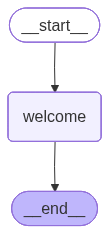

In [8]:
from IPython.display import display
display(my_graph)

In [12]:
first_response=my_graph.invoke({"name":"Alice", "message":"hello"})

In [14]:
first_response

{'name': 'Alice',
 'message': AIMessage(content="Hello Alice! It's nice to meet you. How are you doing today?", additional_kwargs={}, response_metadata={'model': 'llama3.2', 'created_at': '2026-02-26T02:53:15.143371Z', 'done': True, 'done_reason': 'stop', 'total_duration': 827498125, 'load_duration': 122373750, 'prompt_eval_count': 34, 'prompt_eval_duration': 434312167, 'eval_count': 17, 'eval_duration': 257570166, 'logprobs': None, 'model_name': 'llama3.2', 'model_provider': 'ollama'}, id='lc_run--019c97dd-62c8-7be1-ad75-3d5c6a717f12-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 34, 'output_tokens': 17, 'total_tokens': 51})}